# Will they flag? Predicting time-forfeit losses in Lichess blitz

Each row is a snapshot of a blitz game at the moment a player first drops below 60/40/20/10 s thresholds. The target `flagged` says whether that player goes on to lose on time.

Data built with `prepare_data.py`. Berserk (`my_berserk`, `opp_berserk`) is not in the PGN headers, so it is detected from each player's first clock, which is halved when they berserk.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('data/snapshots.csv')
df.head(5)

,game_id,threshold,event,eco,opening,time_control,ply,is_white,my_clock,opp_clock,my_rating,opp_rating,my_material,opp_material,my_berserk,opp_berserk,flagged
0,0Z3mWQw5,60,Rated Blitz game,A22,"English Opening: King's English Variation, Two...",300,56,False,52.0,68.0,1405,1365,22,23,False,False,1
1,0Z3mWQw5,60,Rated Blitz game,A22,"English Opening: King's English Variation, Two...",300,57,True,59.0,52.0,1365,1405,23,22,False,False,0
2,0Z3mWQw5,40,Rated Blitz game,A22,"English Opening: King's English Variation, Two...",300,58,False,36.0,59.0,1405,1365,22,23,False,False,1
3,0Z3mWQw5,40,Rated Blitz game,A22,"English Opening: King's English Variation, Two...",300,63,True,26.0,26.0,1365,1405,23,22,False,False,0
4,0Z3mWQw5,20,Rated Blitz game,A22,"English Opening: King's English Variation, Two...",300,64,False,18.0,26.0,1405,1365,22,23,False,False,1


## 1. Data preparation

### 1.1 Data cleaning

We remove a few anomalies we found when looking at the ranges of values in the EDA.
- Rows where the opponent's clock is above the base time. Lichess lets a player give their opponent +15 s, and in a few games this was used over and over (up to 3,900 s on the clock), which isn't a normal game situation.
- Rows where the snapshot happens in the first 10 plies. Being under 60 s after 5 moves each, in a 3+0 game or longer, means the player spent minutes on the opening. This is most likely a disconnection and not real time trouble.
- Berserk outside of arenas. Berserk only exists in arena tournaments, so the few rows marked as berserk elsewhere come from an unusual first clock, and we set them back to False.

In [2]:
n_rows = len(df)

# opponent was given extra time (+15 s button) until their clock went above the base time
df = df[df["opp_clock"] <= df["time_control"]]

# under 60 s within the first 10 plies, most likely a disconnection
df = df[df["ply"] > 10]

# berserk only exists in arenas
not_arena = ~df["event"].str.contains("tournament")
n_fake_berserk = (not_arena & (df["my_berserk"] | df["opp_berserk"])).sum()
df.loc[not_arena, ["my_berserk", "opp_berserk"]] = False

df = df.reset_index(drop=True)
print(f"{n_rows - len(df)} rows removed, {len(df)} left, {n_fake_berserk} berserk flags fixed")

36 rows removed, 160682 left, 49 berserk flags fixed


### 1.2 Feature engineering

Added features:
- `clock_diff` : Clock difference between my clock and opponent's clock (positive = I have more time)
- `clock_ratio` : Ratio between my clock and opponent's clock (ratio > 1 => I have more time) this may capture some non-linear relationship, since a 5 s gap matters more at 10 s vs 15 s than at 50 s vs 55 s (we add +1 to numerator and denominator because sometimes opp_clock is 0)
- `my_clock_frac` : Fraction of the base time left on my clock (60 s is 0.33 in 3+0 but 0.1 in 10+0)
- `opp_clock_frac` : Fraction of the base time left on the opponent's clock
- `rating_diff` : Rating difference between me and opponent
- `material_diff` : Material difference in the board state between me and opponent
- `eco_letter` : First letter of ECO opening code
- `opening_family` : General opening, the part of the opening name before the `:` (e.g. `Sicilian Defense`)
- `is_gambit` : Whether the opening name contains "Gambit"
- `is_arena` : Whether this game was played in a Lichess arena tournament, where players can berserk (halve their clock for an extra point). Swiss tournaments have no berserk.

In [3]:
df["clock_diff"] = df["my_clock"] - df["opp_clock"]
df["clock_ratio"] = (df["my_clock"] + 1) / (df["opp_clock"] + 1) # avoids dividing by 0
df["my_clock_frac"] = df["my_clock"] / df["time_control"]
df["opp_clock_frac"] = df["opp_clock"] / df["time_control"]
df["rating_diff"] = df["my_rating"] - df["opp_rating"]
df["material_diff"] = df["my_material"] - df["opp_material"]
df["eco_letter"] = df["eco"].str[0]
df["opening_family"] = df["opening"].str.split(":").str[0] # "Family: Variation, Subvariation"
df["is_gambit"] = df["opening"].str.contains("Gambit")
df["is_arena"] = df["event"].str.contains("tournament") # "tournament" = arena, swiss events say "swiss"

# categorical: each time control is its own kind of game (done last, the frac features above need it as a number)
df["time_control"] = df["time_control"].astype(str)


### 1.3 Opening families

`opening_family` has 134 values and most of them are rare. We keep the `N_FAMILIES` most common families and group the rest into `Other`.

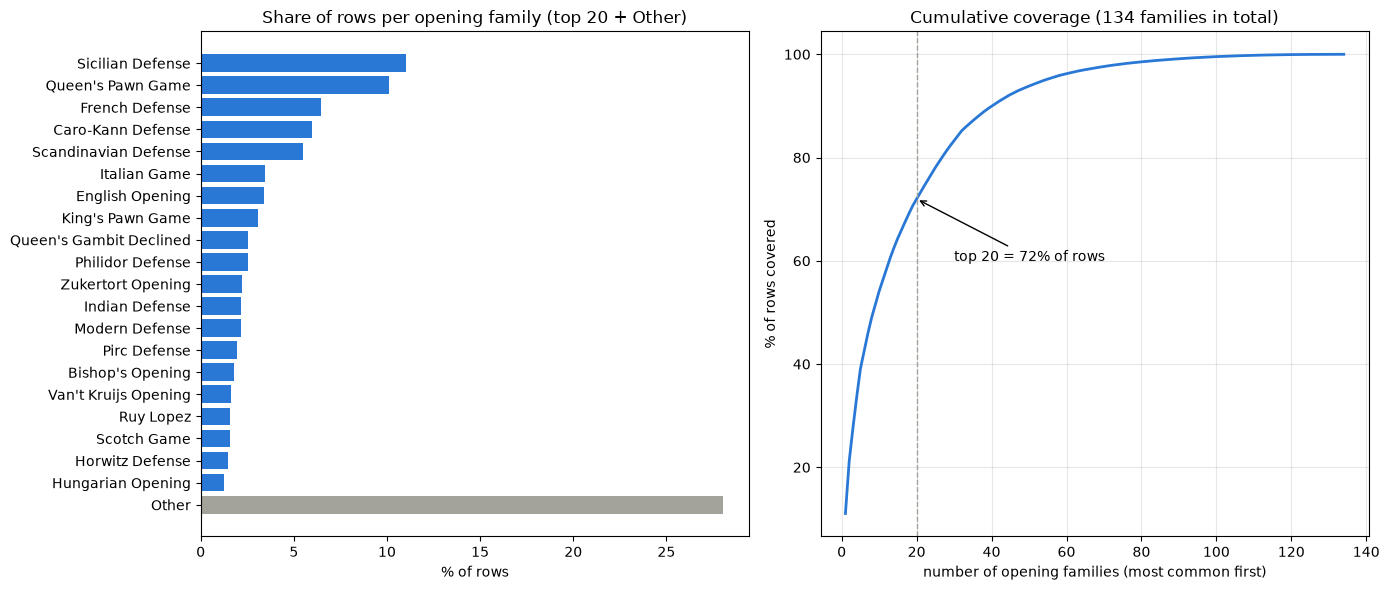

In [4]:
N_FAMILIES = 20 # number of opening families kept, the rest becomes "Other"

families = df["opening"].str.split(":").str[0]
shares = families.value_counts(normalize=True)
plot_shares = pd.concat([shares.head(N_FAMILIES), pd.Series({"Other": shares.iloc[N_FAMILIES:].sum()})])
coverage = shares.cumsum().reset_index(drop=True)
coverage.index += 1 # x axis = number of families kept

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

colors = ["#2a78d6"] * N_FAMILIES + ["#a3a29b"] # Other in gray
ax1.barh(plot_shares.index[::-1], plot_shares.values[::-1] * 100, color=colors[::-1])
ax1.set_xlabel("% of rows")
ax1.set_title(f"Share of rows per opening family (top {N_FAMILIES} + Other)")

ax2.plot(coverage.index, coverage.values * 100, color="#2a78d6", linewidth=2)
ax2.axvline(N_FAMILIES, color="#a3a29b", linestyle="--", linewidth=1)
ax2.annotate(f"top {N_FAMILIES} = {coverage[N_FAMILIES]:.0%} of rows", (N_FAMILIES, coverage[N_FAMILIES] * 100),
             xytext=(N_FAMILIES + 10, coverage[N_FAMILIES] * 100 - 12), arrowprops=dict(arrowstyle="->"))
ax2.set_xlabel("number of opening families (most common first)")
ax2.set_ylabel("% of rows covered")
ax2.set_title(f"Cumulative coverage ({len(shares)} families in total)")
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [5]:
top_families = df["opening_family"].value_counts().head(N_FAMILIES).index
df["opening_family"] = df["opening_family"].where(df["opening_family"].isin(top_families), "Other")

### 1.4 Missing values and types

We verify the non-null count and datatypes of our dataframe with `df.info()`. The Non-Null Count of every column should equal the number of rows (160,682)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160682 entries, 0 to 160681
Data columns (total 27 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   game_id         160682 non-null  str    
 1   threshold       160682 non-null  int64  
 2   event           160682 non-null  str    
 3   eco             160682 non-null  str    
 4   opening         160682 non-null  str    
 5   time_control    160682 non-null  str    
 6   ply             160682 non-null  int64  
 7   is_white        160682 non-null  bool   
 8   my_clock        160682 non-null  float64
 9   opp_clock       160682 non-null  float64
 10  my_rating       160682 non-null  int64  
 11  opp_rating      160682 non-null  int64  
 12  my_material     160682 non-null  int64  
 13  opp_material    160682 non-null  int64  
 14  my_berserk      160682 non-null  bool   
 15  opp_berserk     160682 non-null  bool   
 16  flagged         160682 non-null  int64  
 17  clock_diff      16068

There are no missing values and every column has the type we expect, so there is nothing else to clean.

## 2. Validation framework

60/20/20 train/val/test split by `game_id`, with a fixed `random_state`.

### 2.1 Group split by `game_id`

Since we can take up to 8 snapshots of a given game (4 thresholds * 2 players), we may have many rows for one game. These rows are heavily correlated and we wouldn't want our model to get evaluated on a row from a game it's already seen through another row in its training set. So we split on `game_id` and make sure that every row of a game goes to the same split bucket.

In [7]:
from sklearn.model_selection import train_test_split

games = df["game_id"].unique()
games_full_train, games_test = train_test_split(games, test_size=0.2, random_state=1)
games_train, games_val = train_test_split(games_full_train, test_size=0.25, random_state=1)

df_full_train = df[df["game_id"].isin(games_full_train)].reset_index(drop=True)
df_train = df[df["game_id"].isin(games_train)].reset_index(drop=True)
df_val = df[df["game_id"].isin(games_val)].reset_index(drop=True)
df_test = df[df["game_id"].isin(games_test)].reset_index(drop=True)

We then verify that no `game_id` is shared between different buckets and print the size of each split bucket

In [8]:
train_ids, val_ids, test_ids = set(df_train["game_id"]), set(df_val["game_id"]), set(df_test["game_id"])
assert not (train_ids & val_ids) and not (train_ids & test_ids) and not (val_ids & test_ids)
print(len(df_train), len(df_val), len(df_test))

96437 32155 32090


### 2.2 Target and dropped columns

We extract our target column and drop the columns the model shouldn't use, which are `game_id` (only needed for the split), `opening` (replaced by `opening_family`) and `event` (replaced by `is_arena`).

In [9]:
y_train = df_train["flagged"].values
y_val = df_val["flagged"].values
y_test = df_test["flagged"].values

for d in (df_train, df_val, df_test):
    del d["flagged"]
    del d["game_id"]
    del d["opening"] # we're keeping opening_family
    del d["event"] # not needed anymore, all info is in time_control and is_arena

## 3. EDA

In this section we only use `df_full_train`, so the test set stays unseen. We start with the column types, the ranges of values and the target, then look at how the flagging rate changes with each categorical feature, with a closer look at time control and berserk since both give surprising results at first. We finish with feature importance (mutual information and correlation), the flagging rate per clock difference and the risk per opening family.

### 3.1 Column types

We treat `time_control` as categorical even though it's a number. Its order and the size of the gaps between time controls are already reflected in `my_clock_frac` and `opp_clock_frac`. Also, 3+0, 5+0 and 10+0 feel like different games to players, each with its own mindset, and some players only play one of them, so we let the model learn a separate effect for each.

In [10]:
num_cols = ["threshold", "ply", "my_clock", "opp_clock", "my_rating",
            "opp_rating", "my_material", "opp_material", "clock_diff", 
            "clock_ratio", "my_clock_frac", "opp_clock_frac", "rating_diff",
            "material_diff"]
cat_cols = ["time_control", "is_white", "my_berserk", "opp_berserk", "eco_letter",
            "opening_family", "is_gambit", "is_arena"]
target   = ["flagged"]

### 3.2 Ranges of values

In [11]:
# ranges of values
df_full_train[num_cols].describe().round(2)

,threshold,ply,my_clock,opp_clock,my_rating,opp_rating,my_material,opp_material,clock_diff,clock_ratio,my_clock_frac,opp_clock_frac,rating_diff,material_diff
count,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00,128592.00
mean,38.87,72.65,34.57,72.31,1685.22,1690.14,17.88,17.56,-37.74,1.13,0.17,0.31,-4.92,0.32
std,18.96,23.20,18.37,61.58,367.46,366.51,8.61,8.63,61.66,2.58,0.10,0.19,119.44,4.96
min,10.00,11.00,0.00,0.00,400.00,432.00,0.00,0.00,-579.00,0.00,0.00,0.00,-1372.00,-49.00
25%,20.00,56.00,18.00,31.00,1441.00,1447.00,11.00,11.00,-59.00,0.31,0.08,0.14,-35.00,-2.00
50%,40.00,69.00,37.00,61.00,1718.00,1725.00,18.00,17.00,-26.00,0.56,0.17,0.29,-1.00,0.00
75%,60.00,85.00,54.00,95.00,1944.00,1947.00,25.00,24.00,0.00,1.00,0.23,0.45,30.00,3.00
max,60.00,284.00,59.00,590.00,3054.00,3055.00,49.00,49.00,59.00,60.00,0.33,0.98,1639.00,49.00


In [12]:
df_full_train[cat_cols].nunique()

time_control       3
is_white           2
my_berserk         2
opp_berserk        2
eco_letter         5
opening_family    21
is_gambit          2
is_arena           2
dtype: int64

### 3.3 Target variable

Here we can see the average flagging rate across our dataset (about 39%, so the classes aren't too imbalanced), and we will explore what features impact the flagging rate the most.

In [13]:
df_full_train.flagged.value_counts(normalize=True)

flagged
0    0.609315
1    0.390685
Name: proportion, dtype: float64

We also verify if the mean of our target in our splits are consistent enough:

In [14]:
y_train.mean(), y_val.mean(), y_test.mean()

(np.float64(0.39017182201851985),
 np.float64(0.39222515938423264),
 np.float64(0.39414147709566844))

### 3.4 Flagging rate per category (risk ratio)

When we interpret these results, it's important to remind ourselves what the rows in our dataframe actually represent. They are snapshots of games once a given player is below some threshold of time (below 60/40/20/10 seconds). So when we compare flagging rates between time controls for example, we are actually comparing how often players flag once their clock is below the **same time** across different base times.

Games where no player ever drops below a threshold don't appear in our data at all, so these rates are not how often players flag in each time control in general.

In [15]:
global_rate = df_full_train.flagged.mean()

groups = []
for col in cat_cols:
    df_group = df_full_train.groupby(col).flagged.agg(["mean", "count"])
    df_group["diff"] = df_group["mean"] - global_rate
    df_group["risk"] = df_group["mean"] / global_rate
    df_group.index = df_group.index.astype(str) # bools, ints and strings in one index
    groups.append(df_group.sort_values("risk"))

risk_table = pd.concat(groups, keys=cat_cols, names=["feature", "value"])

risk_format = {"mean": "{:.3f}", "count": "{:,}", "diff": "{:+.3f}", "risk": "{:.3f}"}

# opening_family has its own table further down
shown = risk_table.drop("opening_family", level="feature")

# a line above the first row of each feature
is_first = ~shown.index.get_level_values("feature").duplicated()
line = np.where(is_first, "border-top: 2px solid gray", "")

(shown.style
    .format(risk_format)
    .background_gradient(subset=["risk"], cmap="RdBu_r", vmin=0.7, vmax=1.3)
    .apply(lambda col: line)          # line on the data cells
    .apply_index(lambda idx: line))   # line on the index cells

### 3.5 Time control

If we take a look at the flagging rate per time control (0.36, 0.45 and 0.53 for 3+0, 5+0 and 10+0), it might seem counterintuitive that players in longer time controls flag more often, but that's an erroneous interpretation. We have to remember that all rows are moments when a player is **already** low on time, so the correct interpretation is: when a player in a long time control is low on time, they have higher flagging chances than when a player in a short time control falls to the same low time threshold. Indeed, the following table tells us why. When a player is at a low time threshold on longer time controls, their opponent usually has more time left, which means it's less likely that the opponent is the one who flags:

In [16]:
# opponent's clock at the moment a player first drops below 10 s, per time control
low_time = df_full_train[df_full_train["threshold"] == 10]
low_time_table = low_time.groupby("time_control").agg(
    opp_clock_mean=("opp_clock", "mean"),
    opp_clock_median=("opp_clock", "median"),
    flag_rate=("flagged", "mean"),
    count=("flagged", "count"),
)

(low_time_table.style
    .set_caption("Opponent's clock and flagging rate when a player first drops below 10 s")
    .format({"opp_clock_mean": "{:.1f}", "opp_clock_median": "{:.0f}", "flag_rate": "{:.2f}", "count": "{:,}"})
    .background_gradient(subset=["flag_rate"], cmap="Blues", vmin=0, vmax=1)
    .set_properties(subset=["flag_rate"], **{"font-weight": "bold"})
    .set_table_styles([{"selector": "caption", "props": "font-size: 1.1em; font-weight: bold;"}]))

,opp_clock_mean,opp_clock_median,flag_rate,count
time_control,,,,
180,37.2,31,0.59,"13,230"
300,66.6,57,0.68,"4,469"
600,167.2,156,0.73,"1,479"


The same effect appears at every threshold, not only at 10 s.

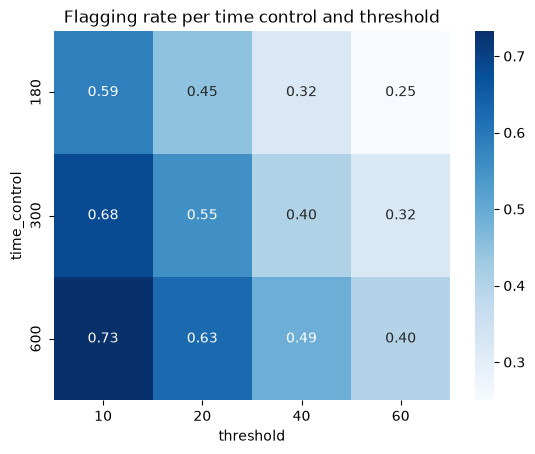

In [17]:
rate = df_full_train.groupby(["time_control", "threshold"]).flagged.mean().unstack()
sns.heatmap(rate, annot=True, fmt=".2f", cmap="Blues")
plt.title("Flagging rate per time control and threshold")
plt.show()

Looking at this made me realise that we should add the `my_clock_frac` feature so that the model could generalize better across time controls.

### 3.6 Berserk

Looking at the berserk rows of the risk table, it's also surprising that players who berserk flag less (0.34) than players who don't (0.39), since they start with half the time. `opp_berserk` makes sense, since if my opponent berserked, they're the one short on time. For `my_berserk`, we have to remember that berserking is a choice made before the game, and players mostly berserk when they expect to win. In the table below (arena games only), berserkers are rated ~190 points higher on average and are usually stronger than their opponent, even though they're further behind on the clock at the snapshot. So berserking is a sign of a stronger player noticing a good matchup.

In [18]:
# berserk is only possible in arenas: who chooses to berserk?
arena = df_full_train[df_full_train["is_arena"]]
arena.groupby("my_berserk").agg(
    my_rating_mean=("my_rating", "mean"),
    rating_diff_mean=("rating_diff", "mean"),
    clock_diff_median=("clock_diff", "median"),
    flag_rate=("flagged", "mean"),
    count=("flagged", "count"),
).round(2)

,my_rating_mean,rating_diff_mean,clock_diff_median,flag_rate,count
my_berserk,,,,,
False,1721.05,-75.15,-18.0,0.42,13561
True,1906.69,132.02,-53.0,0.34,4898


### 3.7 Feature importance: mutual information

Mutual information measures how much knowing each categorical feature tells us about `flagged`. Higher means more informative.

In [19]:
from sklearn.metrics import mutual_info_score

mi = df_full_train[cat_cols].apply(lambda s: mutual_info_score(s, df_full_train.flagged))
mi.sort_values(ascending=False)

time_control      0.005609
opening_family    0.000348
my_berserk        0.000242
opp_berserk       0.000070
eco_letter        0.000062
is_gambit         0.000028
is_white          0.000025
is_arena          0.000006
dtype: float64

### 3.8 Feature importance: correlation

Correlation of each numerical feature with `flagged`. The sign gives the direction and the size gives the strength.

In [20]:
df_full_train[num_cols].corrwith(df_full_train.flagged).sort_values()

my_clock_frac    -0.283370
my_clock         -0.281429
clock_diff       -0.279836
threshold        -0.243617
clock_ratio      -0.200607
ply              -0.140860
my_rating        -0.095712
rating_diff      -0.085296
material_diff    -0.074726
opp_rating       -0.068164
my_material       0.115626
opp_material      0.158361
opp_clock_frac    0.186252
opp_clock         0.196249
dtype: float64

### 3.9 Flagging rate vs clock difference

Correlation only captures linear effects, so we also bin `clock_diff` (my clock − opponent's clock, in seconds) and look at the flagging rate in each bin.

In [21]:
bins = pd.cut(df_full_train.clock_diff, [-600, -60, -20, -5, 5, 20, 60, 600])
df_full_train.groupby(bins, observed=True).flagged.agg(["mean", "count"])

,mean,count
clock_diff,,
"(-600, -60]",0.581137,32063
"(-60, -20]",0.465823,39676
"(-20, -5]",0.385010,18319
"(-5, 5]",0.288036,12922
"(5, 20]",0.132970,13582
"(20, 60]",0.045137,12030


### 3.10 Opening families

Risk per opening family, sorted.

In [22]:
(risk_table.loc["opening_family"].sort_values("risk")
    .style.format(risk_format)
    .background_gradient(subset=["risk"], cmap="RdBu_r", vmin=0.7, vmax=1.3))

,mean,count,diff,risk
value,,,,
Hungarian Opening,0.366,"1,551",-0.025,0.936
Sicilian Defense,0.372,"14,234",-0.019,0.953
Scotch Game,0.374,"2,037",-0.017,0.957
Queen's Gambit Declined,0.375,"3,441",-0.016,0.960
Modern Defense,0.377,"2,862",-0.014,0.965
Italian Game,0.383,"4,471",-0.008,0.980
Pirc Defense,0.385,"2,526",-0.005,0.986
Other,0.388,"36,276",-0.003,0.993
English Opening,0.391,"4,324",+0.000,1.000


## 4. Models

Metric: ROC AUC on validation.

### 4.1 Logistic regression (baseline), tune `C`

### 4.2 Decision tree, tune `max_depth`, `min_samples_leaf`

### 4.3 Random forest, tune `n_estimators`, `max_depth`, `min_samples_leaf`

### 4.4 XGBoost, tune `eta`, `max_depth`, `min_child_weight`

## 5. Model selection

Comparison table of validation AUCs, pick the best, retrain on train+val, check on test.